# 1. Introduction

Music recommendation systems help listeners discover tracks based on their musical preferences and the characteristics of songs. Audio features such as danceability, energy, acousticness and tempo can provide useful information about how tracks differ from or resemble one another.

This project investigates whether Spotify track data could be used to identify musical similarities and support the development of a music recommendation system. The analysis will focus on understanding the dataset, assessing data quality and exploring relationships between audio features before considering the development of a recommendation algorithm.

The analysis will address three research questions:

1. Which audio features may be useful for identifying similarities between songs?
2. What relationships exist between Spotify's audio features?
3. How suitable is the dataset for developing a music recommendation system?

The findings will help establish whether the dataset is suitable for further analysis and provide a foundation for future recommendation modelling.

In [1]:
import pandas as pd

df = pd.read_csv(
    "hf://datasets/maharshipandya/spotify-tracks-dataset/dataset.csv"
)

pd.set_option('display.max_columns', None)

## 2. Dataset Overview

The Spotify tracks dataset contains information about individual tracks, including track metadata and audio features. Before cleaning or analysing the data, I will examine its dimensions, column names, data types and initial records to understand its structure.

In [2]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [3]:
df.shape

(114000, 21)

In [4]:
df.columns

Index(['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name',
       'popularity', 'duration_ms', 'explicit', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'track_genre'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [6]:
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


## 3. Data Quality Assessment

Before analysing the relationships between Spotify audio features, I will assess the dataset for missing values, duplicate records and potential inconsistencies. This will help establish whether the data is sufficiently complete and reliable for the planned analysis.

In [7]:
df.isnull().sum()

#Counts the missing values in each column. Helps us confirm if only three columns identified in df.info().

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [8]:
df[df.isnull().any(axis=1)]

#Displays rows containing at least one missing value. Can check whether the three missing entries belong to the same track record.

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [9]:
df.duplicated().sum()

#This counts rows that are exact duplicates of earlier rows across all columns.

np.int64(0)

In [10]:
df['track_id'].duplicated().sum()

#Checks for duplicated track IDs. Repeated IDs are not automatically errors, but they may matter if we later want to recommend unique tracks.

np.int64(24259)

In [11]:
df['Unnamed: 0'].head(10)

0    0
1    1
2    2
3    3
4    4
5    5
6    6
7    7
8    8
9    9
Name: Unnamed: 0, dtype: int64

In [12]:
df['Unnamed: 0'].nunique()

#These will help us understand whether the column simply contains a unique row index or something else.

114000

In [13]:
# Find track IDs that appear more than once
repeated_ids = df[df['track_id'].duplicated(keep=False)]

# Display examples, sorted by track ID
repeated_ids.sort_values('track_id').head(10)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
15028,15028,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,1,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,chill
103211,103211,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,1,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,soul
85578,85578,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,2,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,punk-rock
100420,100420,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,2,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,ska
91801,91801,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,1,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,rock
3257,3257,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,1,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alternative
2106,2106,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,1,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alt-rock
33178,33178,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,5,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,emo
94239,94239,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,5,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,sad
97533,97533,006rHBBNLJMpQs8fRC2GDe,Calcinha Preta;Gusttavo Lima,CP 25 Anos (Ao Vivo em Aracaju),Agora Estou Sofrendo - Ao Vivo,47,260510,False,0.605,0.678,0,-3.257,1,0.0311,0.64200,0.000000,0.1570,0.439,125.059,4,sertanejo


In [14]:
# Count how many different genres each track ID has
df.groupby('track_id')['track_genre'].nunique().value_counts().sort_index()

track_genre
1    73442
2    11424
3     2955
4     1361
5      431
6      104
7       21
8        2
9        1
Name: count, dtype: int64

In [15]:
# Count how many distinct genres each track ID has
genres_per_track = df.groupby('track_id')['track_genre'].nunique()

# Identify track IDs that occur more than once
repeated_track_ids = df['track_id'].value_counts()
repeated_track_ids = repeated_track_ids[repeated_track_ids > 1].index

# Display examples of repeated IDs and their records
df[df['track_id'].isin(repeated_track_ids)].sort_values(
    'track_id'
)[['track_id', 'track_name', 'artists', 'track_genre',
   'popularity', 'danceability', 'energy']].head(20)

,track_id,track_name,artists,track_genre,popularity,danceability,energy
15028,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,chill,0,0.613,0.471
103211,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,soul,0,0.613,0.471
85578,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,punk-rock,38,0.554,0.921
100420,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,ska,38,0.554,0.921
91801,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,rock,86,0.352,0.911
3257,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,alternative,86,0.352,0.911
2106,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,alt-rock,86,0.352,0.911
33178,004h8smbIoAkUNDJvVKwkG,Lovemark,Ouse;Powfu,emo,58,0.808,0.331
94239,004h8smbIoAkUNDJvVKwkG,Lovemark,Ouse;Powfu,sad,58,0.808,0.331
97533,006rHBBNLJMpQs8fRC2GDe,Agora Estou Sofrendo - Ao Vivo,Calcinha Preta;Gusttavo Lima,sertanejo,47,0.605,0.678


In [16]:
# Select the numerical audio features
audio_features = [
    'danceability', 'energy', 'key', 'loudness', 'mode',
    'speechiness', 'acousticness', 'instrumentalness',
    'liveness', 'valence', 'tempo', 'time_signature'
]

# Count distinct values per track ID for each audio feature
df.groupby('track_id')[audio_features].nunique().max()

danceability        1
energy              1
key                 1
loudness            1
mode                1
speechiness         1
acousticness        1
instrumentalness    1
liveness            1
valence             1
tempo               1
time_signature      1
dtype: int64

### Initial Data Quality Findings

The dataset contains 114,000 rows and 21 columns. One record has missing values in `artists`, `album_name` and `track_name`, although its track ID, genre and audio features are present.

No exact duplicate rows were identified. However, some track IDs appear multiple times under different genre labels. Inspection of sample records found that repeated records retain consistent values across all 12 numerical audio features examined. This suggests that repeated IDs reflect the dataset's genre categorisation rather than necessarily being errors. The original records will be retained for now, with the handling of repeated tracks considered during preparation for recommendation modelling.

The `Unnamed: 0` column contains 114,000 unique sequential values, suggesting that it is an exported row index rather than a meaningful feature. It will be considered for removal during data preparation.

## 4. Data Cleaning and Preparation

Following the initial data quality assessment, the dataset will be prepared for exploratory data analysis. This stage involves removing unnecessary columns and addressing missing values where appropriate, while preserving useful information about tracks and their genre classifications. The original dataset will be retained so that cleaning decisions can be made without altering the source data.

In [17]:
# Create a cleaned working dataset without the exported row-index column
df_clean = df.drop(columns=['Unnamed: 0'])

# Confirm the exported index column has been removed
'Unnamed: 0' in df_clean.columns

False

### Handling Missing Metadata

The data quality assessment identified one record with missing values in the `artists`, `album_name` and `track_name` columns. However, the record retains its track ID, genre and numerical audio features. As these features may still be useful for exploratory data analysis, the record will be retained rather than removed at this stage. Analyses and recommendation outputs that require complete track metadata may exclude this record where necessary. The missing values will not be replaced with invented information.

## 5. Exploratory Data Analysis

Exploratory data analysis (EDA) will be used to investigate the distribution of Spotify's audio features and identify patterns that may be useful for music recommendation. This stage will examine the characteristics of individual features, relationships between features and differences between musical genres.

The analysis will focus on features such as danceability, energy, acousticness, instrumentalness, valence and tempo. Visualisations and summary statistics will be used to understand the data, identify potential relationships and assess which features may help distinguish between tracks.

The findings will help determine which audio features are worth considering when developing a music recommendation system in future work.

In [18]:
# Select the audio features for analysis
audio_features = [
    'danceability', 'energy', 'acousticness',
    'instrumentalness', 'valence', 'tempo',
    'speechiness', 'liveness', 'loudness'
]

# Calculate summary statistics
df_clean[audio_features].describe()

,danceability,energy,acousticness,instrumentalness,valence,tempo,speechiness,liveness,loudness
count,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,0.566800,0.641383,0.314910,0.156050,0.474068,122.147837,0.084652,0.213553,-8.258960
std,0.173542,0.251529,0.332523,0.309555,0.259261,29.978197,0.105732,0.190378,5.029337
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-49.531000
25%,0.456000,0.472000,0.016900,0.000000,0.260000,99.218750,0.035900,0.098000,-10.013000
50%,0.580000,0.685000,0.169000,0.000042,0.464000,122.017000,0.048900,0.132000,-7.004000
75%,0.695000,0.854000,0.598000,0.049000,0.683000,140.071000,0.084500,0.273000,-5.003000
max,0.985000,1.000000,0.996000,1.000000,0.995000,243.372000,0.965000,1.000000,4.532000


### Summary Statistics

The summary statistics show variation across the selected audio features. Danceability, energy and valence are measured on a scale from 0 to 1, while tempo and loudness use different units. This means that the numerical values of different features should not be compared directly without considering their scales.

Acousticness, instrumentalness, speechiness and liveness have means that exceed their medians, suggesting that higher values may influence their averages. Instrumentalness has a particularly low median, indicating that at least half of the records have very low instrumentalness values.

All nine selected features contain 114,000 observations, with no missing values. However, the minimum tempo of zero and the wide range of loudness values warrant further investigation. Histograms will be used next to examine the distributions and identify any potentially unusual values.

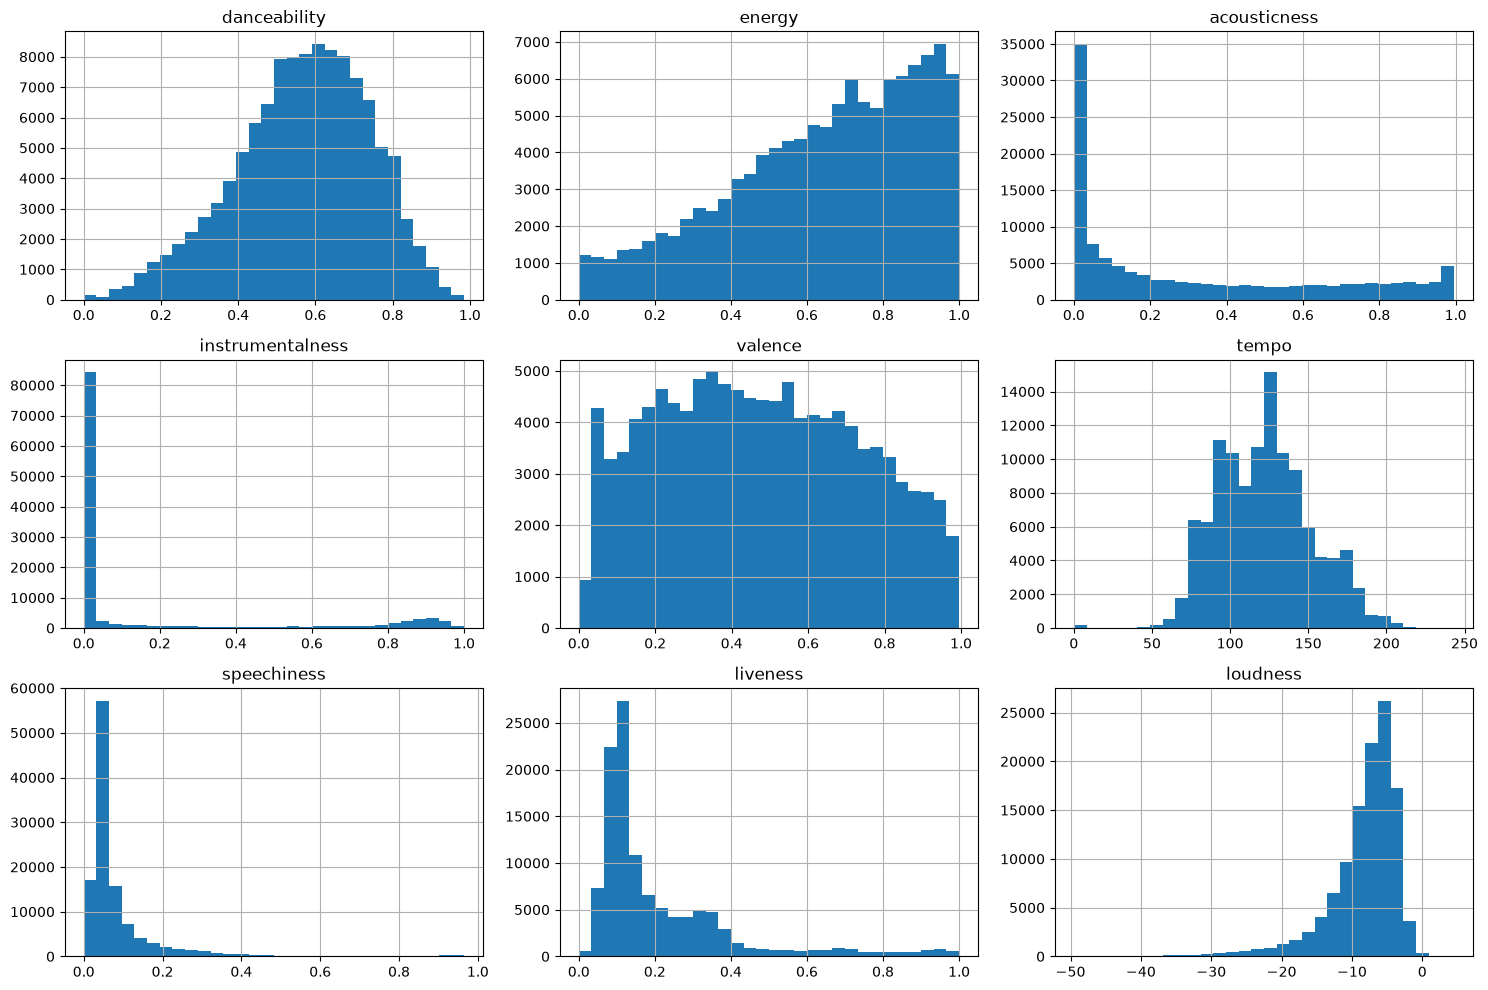

In [19]:
import matplotlib.pyplot as plt

# Plot the distribution of each selected audio feature
df_clean[audio_features].hist(
    figsize=(15, 10),
    bins=30
)

plt.tight_layout()
plt.show()

### Audio Feature Distributions

The histograms reveal considerable variation in the distributions of Spotify's audio features. Danceability is concentrated around the middle of its scale, while energy values tend to be higher. Valence is more widely distributed, indicating variation in the musical mood represented by this feature.

Acousticness, instrumentalness, speechiness and liveness are strongly right-skewed, with most tracks having relatively low values and fewer tracks having high values. In particular, instrumentalness is concentrated very close to zero.

Tempo is mainly concentrated between approximately 80 and 160 BPM, while loudness values are concentrated in a narrower range with a tail towards lower values. The histograms also highlight potentially unusual observations, particularly a tempo value near zero and extreme loudness values.

These distributions suggest that the selected features capture different characteristics of tracks and may contribute useful information to a future recommendation system. However, further analysis is needed to investigate relationships between features and determine how they could be used to identify similar tracks.

In [20]:
# Find tracks with a tempo of zero
df_clean[df_clean['tempo'] == 0][
    ['track_id', 'track_name', 'artists', 'track_genre', 'tempo']
]

,track_id,track_name,artists,track_genre,tempo
4131,59gg6zQhSKGVnkT3hWAY3l,The Departure,Max Richter;Lang Lang,ambient,0.0
4379,4acmzQsAeMJa5sGFSog7fu,The End of Childhood (feat. Jack Liebeck),Dario Marianelli;Jack Liebeck;Benjamin Wallfisch,ambient,0.0
4664,1Kb2DqjHRvOcT5xeWtz3t5,Ferme Les Yeux,Sylvain Chauveau,ambient,0.0
45670,6B9Mgf9smWqxDjA35VD6MK,Campomoro,Little Symphony,guitar,0.0
45720,7i5OoyPXtSrqz9jobJfG1F,Ritornello,Little Symphony,guitar,0.0
...,...,...,...,...,...
101988,5gEKRH0MCSegG8ZISUPaU2,Tin White Noise,Granular,sleep,0.0
101993,6H0kAiSAFB84jX7dgEDWd6,Rain: Natural Recording,Rain Sounds,sleep,0.0
113428,5EYzrykQ95uOmepteDi9KT,Aire de verano,El Ruido Blanco;Soñoliento Juan;Mantra para Do...,world-music,0.0
113688,2EnZf7wbFv7ST4CJ3EvNzT,Ruido Rosa Puro - Una Hora Versión,El Ruido Blanco,world-music,0.0


In [21]:
# Count tracks with a tempo of zero
zero_tempo_count = (df_clean['tempo'] == 0).sum()

# Calculate the percentage of the dataset
zero_tempo_percentage = zero_tempo_count / len(df_clean) * 100

print(f"Tracks with zero tempo: {zero_tempo_count}")
print(f"Percentage of dataset: {zero_tempo_percentage:.2f}%")

Tracks with zero tempo: 157
Percentage of dataset: 0.14%


### Investigation of Zero-Tempo Records

The tempo histogram revealed a small number of records with a tempo of zero. Further investigation identified 157 such records, representing approximately 0.14% of the dataset. The sample includes ambient music, sleep music and sound recordings, suggesting that some tracks may not have a conventional or easily detectable beat.

A tempo value of zero may indicate that a tempo was not detected rather than representing a meaningful tempo measurement. These records will be retained in the cleaned dataset at this stage, as removing them could exclude potentially valid tracks. If tempo is used in future recommendation modelling, these records may require separate treatment to avoid misleading comparisons.

In [22]:
# Calculate correlations between audio features
correlation_matrix = df_clean[audio_features].corr()

correlation_matrix

,danceability,energy,acousticness,instrumentalness,valence,tempo,speechiness,liveness,loudness
danceability,1.000000,0.134325,-0.171533,-0.185606,0.477341,-0.050450,0.108626,-0.131617,0.259077
energy,0.134325,1.000000,-0.733906,-0.181879,0.258934,0.247851,0.142509,0.184796,0.761690
acousticness,-0.171533,-0.733906,1.000000,0.104027,-0.107070,-0.208224,-0.002186,-0.020700,-0.589803
instrumentalness,-0.185606,-0.181879,0.104027,1.000000,-0.324312,-0.050330,-0.089616,-0.079893,-0.433477
valence,0.477341,0.258934,-0.107070,-0.324312,1.000000,0.078273,0.036635,0.019086,0.279848
tempo,-0.050450,0.247851,-0.208224,-0.050330,0.078273,1.000000,0.017273,0.000600,0.212446
speechiness,0.108626,0.142509,-0.002186,-0.089616,0.036635,0.017273,1.000000,0.205219,0.060826
liveness,-0.131617,0.184796,-0.020700,-0.079893,0.019086,0.000600,0.205219,1.000000,0.076899
loudness,0.259077,0.761690,-0.589803,-0.433477,0.279848,0.212446,0.060826,0.076899,1.000000


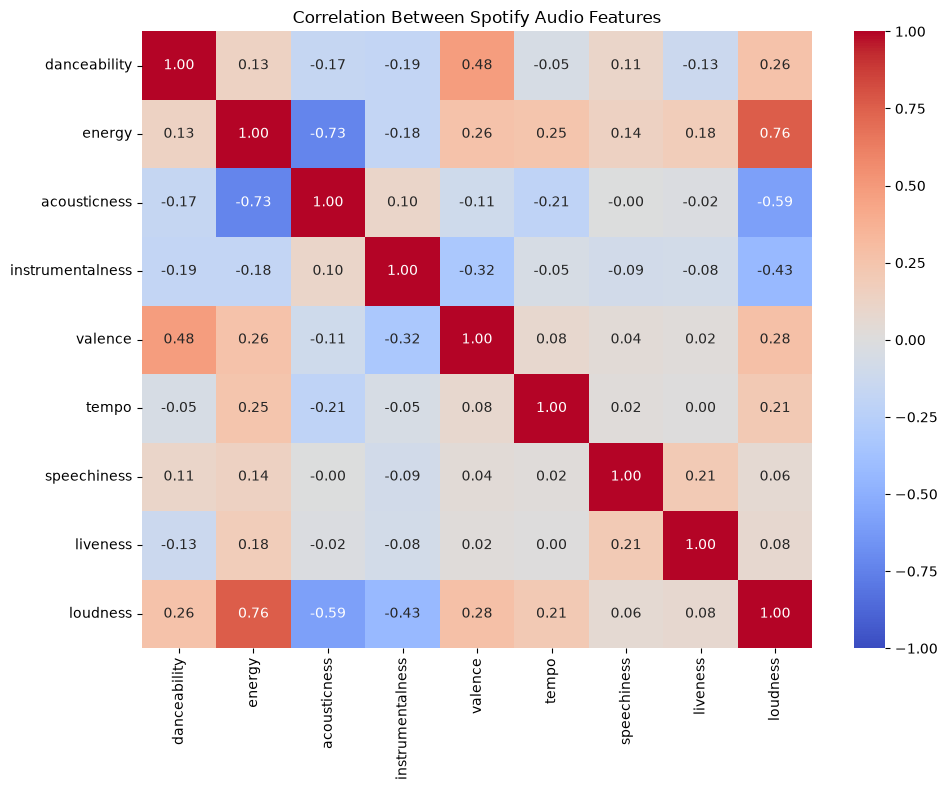

In [23]:
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Between Spotify Audio Features')
plt.tight_layout()
plt.show()

### Correlation Analysis

The correlation analysis identified several relationships between Spotify's audio features. The strongest positive correlation was between energy and loudness (0.762), indicating that higher-energy tracks tend to have higher loudness values. Energy and acousticness had a strong negative correlation (-0.734), suggesting that higher-energy tracks tend to have lower acousticness scores.

A moderate positive correlation was observed between danceability and valence (0.477), while acousticness and loudness (-0.590) and instrumentalness and loudness (-0.433) showed negative relationships. In contrast, several feature pairs, including tempo and liveness, had correlations close to zero.

These results suggest that some audio features capture related characteristics, while others provide different information about tracks. This is relevant to recommendation modelling because combining multiple features may help identify similar songs. However, strongly correlated features may provide overlapping information, and their usefulness should be evaluated in the context of the recommendation method. Correlation indicates association rather than causation.

In [24]:
# Count records for each genre
df_clean['track_genre'].value_counts()

track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
               ... 
techno         1000
trance         1000
trip-hop       1000
turkish        1000
world-music    1000
Name: count, Length: 114, dtype: int64

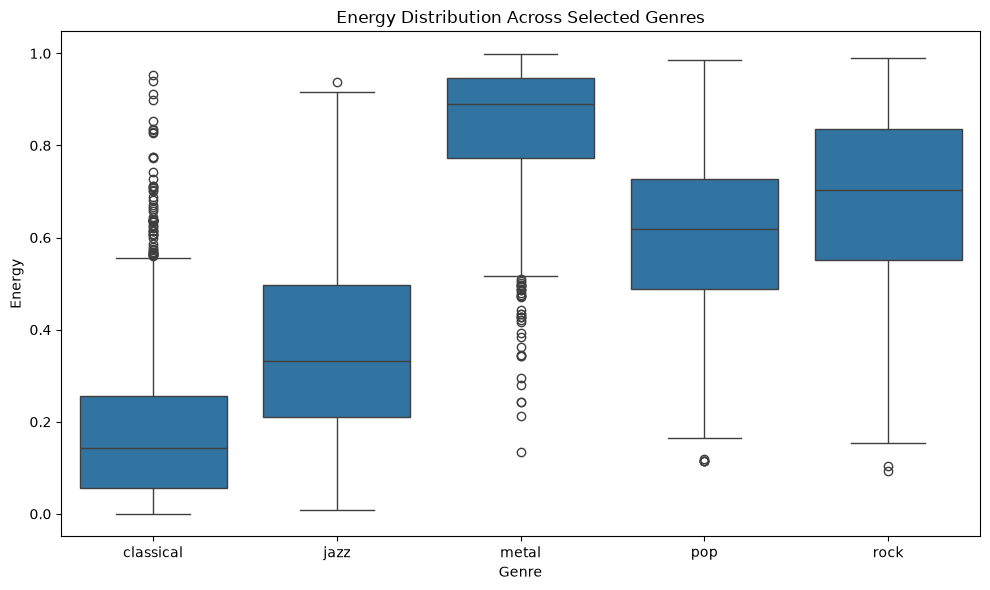

In [25]:
# Select five genres for comparison
selected_genres = [
    'pop', 'rock', 'classical', 'jazz', 'metal'
]

genre_data = df_clean[
    df_clean['track_genre'].isin(selected_genres)
]

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=genre_data,
    x='track_genre',
    y='energy'
)

plt.title('Energy Distribution Across Selected Genres')
plt.xlabel('Genre')
plt.ylabel('Energy')
plt.tight_layout()
plt.show()

### Energy Distribution Across Genres

The boxplot shows clear differences in the energy distributions of the five selected genres. Classical tracks have the lowest median energy, at approximately 0.14, while metal tracks have the highest, at approximately 0.89. Jazz has a median of around 0.33, compared with approximately 0.62 for pop and 0.70 for rock.

The distributions also reveal variation within each genre. Pop and rock have relatively wide distributions, while classical and metal contain several observations outside their main ranges. These outliers may represent genuine differences between individual tracks and should not automatically be treated as errors.

The results suggest that energy could help distinguish some musical styles. However, the overlap between genres indicates that energy alone is unlikely to be sufficient for identifying similar tracks. Combining multiple audio features may provide a more useful basis for future recommendation modelling.

In [26]:
# Calculate summary statistics for acousticness by genre
acousticness_by_genre = (
    df_clean.groupby('track_genre')['acousticness']
    .agg(['mean', 'median', 'std', 'count'])
    .sort_values('median')
)

acousticness_by_genre

,mean,median,std,count
track_genre,,,,
grindcore,0.008698,0.000015,0.048092,1000
black-metal,0.027056,0.000044,0.128681,1000
death-metal,0.006696,0.000131,0.041438,1000
metalcore,0.010286,0.000291,0.048160,1000
heavy-metal,0.014968,0.000431,0.053239,1000
...,...,...,...,...
ambient,0.776790,0.920500,0.301232,1000
romance,0.869495,0.950000,0.191416,1000
new-age,0.824022,0.950000,0.267752,1000


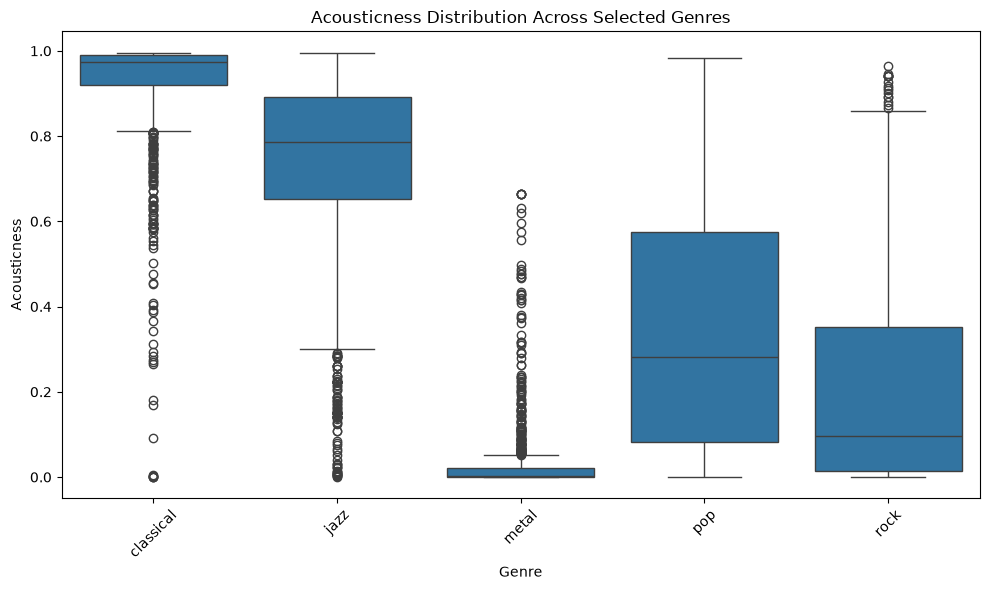

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

selected_genres = ['pop', 'rock', 'classical', 'jazz', 'metal']

acousticness_data = df_clean[
    df_clean['track_genre'].isin(selected_genres)
]

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=acousticness_data,
    x='track_genre',
    y='acousticness'
)

plt.title('Acousticness Distribution Across Selected Genres')
plt.xlabel('Genre')
plt.ylabel('Acousticness')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Relevance to the Energy Distribution Plot:
When cross-referenced with the previously analyzed `energy` distribution plot, a clear **inverse relationship** emerges between these two features across genres:
* **Classical and Metal act as polar opposites:** Classical features maximum acousticness and minimum energy, while Metal features maximum energy and minimum acousticness.
* **Jazz vs. Rock/Pop:** Jazz mirrors Rock and Pop in reverse structural behavior; Jazz keeps a high acoustic/lower energy profile, whereas Rock and Pop lean significantly higher in energy while giving up acoustic dominance.

#### Implications for the Recommendation System:
These distinct, genre-specific profiles directly address our first two research questions. They confirm that `acousticness` and `energy` are highly contrasting features that capture strong variance between different musical styles. Because these distributions map cleanly to recognizable genre differences, both features will be **highly useful inputs for identifying musical similarities** and distinguishing tracks in a recommendation algorithm.


In [28]:
# Create a list of genres for each unique track
aggregation_rules = {
    column: 'first'
    for column in df_clean.columns
    if column not in ['track_id', 'track_genre']
}

aggregation_rules['track_genre'] = (
    lambda genres: sorted(genres.dropna().unique().tolist())
)

df_tracks = (
    df_clean
    .groupby('track_id', as_index=False)
    .agg(aggregation_rules)
)

df_tracks.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0000vdREvCVMxbQTkS888c,Rill,Lolly,Lolly,44,160725,True,0.910,0.374,8,-9.844,0,0.1990,0.075700,0.00301,0.1540,0.432,104.042,4,[german]
1,000CC8EParg64OmTxVnZ0p,Glee Cast,Glee Love Songs,It's All Coming Back To Me Now (Glee Cast Vers...,47,322933,False,0.269,0.516,0,-7.361,1,0.0366,0.406000,0.00000,0.1170,0.341,178.174,4,[club]
2,000Iz0K615UepwSJ5z2RE5,Paul Kalkbrenner;Pig&Dan,X,Böxig Leise - Pig & Dan Remix,22,515360,False,0.686,0.560,5,-13.264,0,0.0462,0.001140,0.18100,0.1110,0.108,119.997,4,[minimal-techno]
3,000RDCYioLteXcutOjeweY,Jordan Sandhu,Teeje Week,Teeje Week,62,190203,False,0.679,0.770,0,-3.537,1,0.1900,0.058300,0.00000,0.0825,0.839,161.721,4,[hip-hop]
4,000qpdoc97IMTBvF8gwcpy,Paul Kalkbrenner,Zeit,Tief,19,331240,False,0.519,0.431,6,-13.606,0,0.0291,0.000964,0.72000,0.0916,0.234,129.971,4,[minimal-techno]


In [29]:

# Compare the original and consolidated dataset sizes
print("Original rows:", len(df_clean))
print("Consolidated rows:", len(df_tracks))
print("Unique track IDs:", df_tracks['track_id'].nunique())

# Confirm that every track ID appears exactly once
print("All track IDs unique:", df_tracks['track_id'].is_unique)

# Check how many genres are associated with each track
print(df_tracks['track_genre'].str.len().value_counts().sort_index())


Original rows: 114000
Consolidated rows: 89741
Unique track IDs: 89741
All track IDs unique: True
track_genre
1    73442
2    11424
3     2955
4     1361
5      431
6      104
7       21
8        2
9        1
Name: count, dtype: int64


In [30]:
print(df_tracks.shape)
print(df_tracks.columns.tolist())
print(df_tracks['track_id'].isna().sum())

(89741, 20)
['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']
0


### Consolidating Duplicate Track IDs

The original dataset contained 114,000 rows, which were consolidated into 89,741 unique tracks by grouping records by `track_id`. Multiple genre labels were combined into lists, while the first value was retained for other columns. Previous checks confirmed that repeated track IDs had consistent audio features.

Validation confirmed that every `track_id` appears exactly once. The consolidated dataset, `df_tracks`, is now better suited for preparing audio features for future recommendation modelling.

### Preparing Audio Features for Recommendation Modelling.

In [31]:
audio_features = [
    'danceability',
    'energy',
    'acousticness',
    'instrumentalness',
    'valence',
    'tempo',
    'speechiness',
    'liveness',
    'loudness'
]

In [32]:
X = df_tracks[audio_features].copy()

X.head()

,danceability,energy,acousticness,instrumentalness,valence,tempo,speechiness,liveness,loudness
0,0.910,0.374,0.075700,0.00301,0.432,104.042,0.1990,0.1540,-9.844
1,0.269,0.516,0.406000,0.00000,0.341,178.174,0.0366,0.1170,-7.361
2,0.686,0.560,0.001140,0.18100,0.108,119.997,0.0462,0.1110,-13.264
3,0.679,0.770,0.058300,0.00000,0.839,161.721,0.1900,0.0825,-3.537
4,0.519,0.431,0.000964,0.72000,0.234,129.971,0.0291,0.0916,-13.606


In [33]:
print(X.isnull().sum())
print(X.describe())

danceability        0
energy              0
acousticness        0
instrumentalness    0
valence             0
tempo               0
speechiness         0
liveness            0
loudness            0
dtype: int64
       danceability        energy  acousticness  instrumentalness  \
count  89741.000000  89741.000000  89741.000000      89741.000000   
mean       0.562166      0.634458      0.328289          0.173413   
std        0.176691      0.256605      0.338321          0.323848   
min        0.000000      0.000000      0.000000          0.000000   
25%        0.450000      0.457000      0.017100          0.000000   
50%        0.576000      0.676000      0.188000          0.000058   
75%        0.692000      0.853000      0.625000          0.097600   
max        0.985000      1.000000      0.996000          1.000000   

            valence         tempo   speechiness      liveness      loudness  
count  89741.000000  89741.000000  89741.000000  89741.000000  89741.000000  
mean       

In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled[:5]

array([[ 1.9686116 , -1.01502053, -0.74660022, -0.5261865 , -0.14257432,
        -0.59820362,  0.98482927, -0.32311399, -0.25758991],
       [-1.65920757, -0.46163775,  0.22969745, -0.53548104, -0.48876346,
         1.86323356, -0.44883143, -0.51297121,  0.21794754],
       [ 0.70085576, -0.29016703, -0.96698397,  0.0234263 , -1.3751598 ,
        -0.06844278, -0.36408302, -0.54375887, -0.91257907],
       [ 0.66123839,  0.52821595, -0.79803098, -0.53548104,  1.40576608,
         1.31693741,  0.90537763, -0.69000024,  0.95030969],
       [-0.24430149, -0.79288801, -0.96750419,  1.68779676, -0.89582101,
         0.2627283 , -0.51504113, -0.64330563, -0.97807799]])

## Conclusion

This project explored and prepared Spotify track data to investigate how audio features can support music recommendation algorithms. The dataset was cleaned by removing an unnecessary index column, investigating missing metadata and consolidating repeated track IDs into 89,741 unique tracks while preserving their genre associations.

Exploratory data analysis examined the distributions and correlations of audio features, alongside comparisons of energy and acousticness across genres. These analyses helped identify differences in musical characteristics and highlighted potentially useful features for measuring track similarity.

Nine numerical audio features were selected for future recommendation modelling. Checks confirmed that the selected feature matrix contained no missing values, and the features were standardised using `StandardScaler` to make their scales more comparable.

Overall, this project established a foundation for a future content-based music recommendation system. However, further work is required to calculate track similarities, generate recommendations and evaluate their quality. Future development could also investigate how genre information and user preferences could improve recommendation relevance.